# 🕸️ PyG 그래프 신경망 네 모델 — Cora 논문 분류로 비교하기

**건설빅데이터분석 · 그래프 신경망 · PyG GNN 네 모델 (Cora) · 실습 노트북 (완성본)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_FourGNN_Cora/cora_gnn4_practice.ipynb) ← **실습본**(빈칸 채우기) &nbsp;&nbsp;[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_FourGNN_Cora/cora_gnn4_complete.ipynb) ← **완성본**(정답·실행결과 포함)

> 강의노트에서 손으로 계산한 네 모델 — **VanillaGNN · GCN · GAT · GraphSAGE** — 를 PyTorch Geometric(PyG)으로 직접 만들어 봅니다.
> 모델마다 먼저 강의노트의 정준 그래프 $G_6$ 에서 **손계산과 똑같은 숫자**가 나오는지 확인하고, 같은 층을 논문 인용 그래프 **Cora**(논문 2,708편)에 올립니다.
> 그래프를 보지 않는 **MLP(기준점)** 와 비교해 이웃 정보가 정확도를 얼마나 올리는지 seed 3개로 잽니다. 마지막에는 시험 노드를 학습 그래프에서 숨기는 **귀납(inductive)** 설정도 해 봅니다.

## 📌 강의 중점
- Cora 그래프 읽기: `edge_index` · 노드 피처 · 마스크(학습 140 · 검증 500 · 시험 1,000) · 준지도 노드 분류
- 네 모델의 집계 규칙을 $G_6$ 손계산 → 코드로: $\tilde A X W^\top$ · $\hat A = \tilde D^{-1/2}\tilde A\tilde D^{-1/2}$ · 어텐션 계수 $\alpha_{ij}$ · 자기 항 + 이웃 평균
- 같은 학습 루프 · 같은 설정 · seed 0·1·2 의 평균 ± 표준편차로 **공정하게 비교** (기준점 MLP 포함)
- 전이(transductive)와 귀납(inductive): 모델이 아니라 **무엇을 나누느냐**가 설정을 정한다

## 🎯 학습 목표
1. Cora 를 PyG 로 불러와 `edge_index`, 피처, 마스크의 모양과 뜻을 설명할 수 있다.
2. $G_6$ 에서 VanillaGNN · GCN · GAT · GraphSAGE 한 층을 손으로 계산하고, 직접 만든 층과 PyG 층(`GCNConv` · `GATConv` · `SAGEConv`)이 같은 값을 내는지 확인할 수 있다.
3. 다섯 모델(MLP 포함)을 같은 조건으로 학습시켜 시험 정확도를 비교하고, seed 에 따른 흔들림을 고려해 해석할 수 있다.
4. 시험 노드를 학습 그래프에서 지우는 귀납 설정을 만들고, 전이 설정과의 차이를 설명할 수 있다.

## 📋 이 노트북 사용법

| 표시 | 뜻 |
|:-:|---|
| ▶ | 셀 실행 — 셀을 클릭하고 `Shift + Enter` |
| 🎬 EP*n* | 이 부분을 설명하는 강의 영상 에피소드 (e-campus) |
| ⏸ | 영상을 멈추고 직접 실행해 보는 지점 |
| ✅ / ❌ | 자가검증 결과 — ❌ 가 나오면 힌트를 읽고 고쳐 보세요 |
| 🔸 | 실험 결과 안내 (오류가 아님) |

**주석(`#` 뒤의 글) 읽는 법** — 실행에는 영향이 없는 설명입니다.
- `1️⃣2️⃣3️⃣4️⃣` 학습 루프 단계 · `①②③④` 손계산 단계 · `💡` 강의노트 연결 · `📐` 텐서 모양(shape) · `⚠️` 흔한 실수 · `✅` 기대 결과 · `⏱` 걸린 시간

**Colab에서 처음 열었다면**
1. 메뉴 **파일 → Drive에 사본 저장** 을 먼저 누르세요. (사본에서 작업해야 내 Drive에 저장됩니다)
2. 첫 코드 셀이 PyTorch Geometric(PyG)이 없으면 설치합니다 (Colab 에서 10초 안쪽). **CPU 런타임 그대로** 모든 셀이 실행됩니다. Colab CPU 에서 노트북 전체가 **약 14분** 걸립니다 (배정된 컴퓨터에 따라 더 걸릴 수 있습니다) — seed 3개로 학습하는 셀이 1~2분씩, 마지막 귀납 비교 셀이 약 6분입니다. Colab 의 PyTorch 버전에 따라 소수점 아래 숫자가 영상과 조금 다를 수 있지만 비교 결론은 같습니다.
3. 위에서부터 **차례대로** 실행하세요. 런타임이 초기화되어 변수가 사라지면 처음부터 다시 실행하면 됩니다.

**🎬 영상과 함께 보는 법 (반복 학습 추천 순서)**
1회차 영상 전체 보기 → 2회차 실습본을 열고 ⏸ 마다 멈추며 따라 치기 → 3회차 영상 없이 빈칸 채우기 → 모든 ✅ 통과 → 끝의 🏆 도전 과제

---
## 0. 준비 — PyG 설치와 라이브러리  🎬 EP1

이 셀에서 할 일: **PyTorch Geometric(PyG)** 이 없으면 설치하고, 오늘 쓸 도구를 불러옵니다.
- PyG 는 PyTorch 위에서 그래프 신경망을 만드는 라이브러리입니다. 그래프 데이터셋(`Planetoid`)과 GNN 층(`GCNConv` · `GATConv` · `SAGEConv`)이 들어 있습니다.
- 이 노트북은 그래프가 작아서 Colab 의 **CPU 런타임**에서 그대로 돌아갑니다 (GPU 필요 없음).
- ⚠️ `Planetoid.url = ...` 줄은 Cora 파일을 받을 주소를 `raw.githubusercontent.com` 으로 바꿉니다. PyG 기본 주소(github.com)는 응답 헤더가 너무 길어져 내려받기 오류(`LineTooLong`)가 납니다. 영상에는 없는 줄입니다.

In [1]:
import importlib.util, subprocess                      # 설치 확인 · 명령 실행 도구
if importlib.util.find_spec("torch_geometric") is None:  # PyG 가 없으면 (Colab 처음 실행)
    subprocess.run(["pip", "install", "-q", "torch_geometric"], check=True)  # 설치
print("PyG 준비 완료")                                 # 이미 있으면 바로 여기로

PyG 준비 완료


In [2]:
import time                                            # 걸린 시간 재기 (⏱)
import torch                                           # PyTorch: 텐서와 신경망
from torch import nn                                   # nn = 신경망 부품(층) 모음
import torch.nn.functional as F                        # F = 렐루 · 드롭아웃 · 손실 함수
import torch_geometric                                 # PyG 본체 (seed 고정 함수)
from torch_geometric.datasets import Planetoid         # Cora 가 들어 있는 데이터셋 묶음
Planetoid.url = "https://raw.githubusercontent.com/kimiyoung/planetoid/master/data"  # ⚠️ 받을 주소
from torch_geometric.nn import GCNConv, GATConv, SAGEConv     # PyG 가 만들어 둔 GNN 층
from torch_geometric.utils import to_dense_adj, to_undirected, subgraph  # 그래프 도구
import pandas as pd                                    # 결과 표
import matplotlib.pyplot as plt                        # 그래프(차트) 그리기

torch.set_printoptions(precision=3, sci_mode=False)    # 소수 3자리, 지수 표기 끄기
print("PyTorch", torch.__version__, "· PyG", torch_geometric.__version__)  # 버전 확인

PyTorch 2.9.1 · PyG 2.7.0


### 자가검증 도우미 `check()` · `check_range()` 준비
아래 셀은 결과가 맞는지 ✅ / ❌ 로 알려 주는 **도우미 함수**입니다.
- `check()` : 기대값과 허용오차(`tol`) 이내로 같으면 ✅ (`tol=0` 이면 완전히 같아야 ✅)
- `check_range()` : 정확도처럼 **범위 안에 들어오면** ✅ (컴퓨터마다 조금씩 달라지는 값에 씁니다)

지금은 내용을 몰라도 괜찮습니다 — **실행만** 해 두세요.

In [3]:
def check(name, value, expected, tol=0.01):  # 자가검증 (이름, 결과, 기대값, 허용오차)
    """value 가 expected 와 tol 이내로 같으면 ✅, 다르면 ❌ 를 보여 줍니다."""
    value = torch.as_tensor(value, dtype=torch.float32)        # 숫자·리스트 → 텐서
    expected = torch.as_tensor(expected, dtype=torch.float32)  # 기대값도 텐서로
    if value.shape != expected.shape:                          # ⚠️ 모양부터 다르면
        print(f"❌ {name}: 모양 {tuple(value.shape)} ≠ 기대 {tuple(expected.shape)}")
        return                                                 # 여기서 끝
    gap = (value - expected).abs().max().item()                # 가장 큰 차이
    mark = "✅" if gap <= tol else "❌"                         # 허용오차 안이면 통과
    tol_s = f"{tol:.6f}".rstrip("0").rstrip(".")               # 0.000001 처럼 보기 좋게
    print(f"{mark} {name}: 최대 차이 {gap:.6f} (허용 {tol_s})")  # 결과 출력

def check_range(name, value, lo, hi):        # 자가검증 (이름, 결과, 최솟값, 최댓값)
    """value 가 lo ~ hi 범위 안이면 ✅, 벗어나면 ❌ 를 보여 줍니다."""
    value = float(value)                                       # 텐서·숫자 → 파이썬 실수
    mark = "✅" if lo <= value <= hi else "❌"                  # 범위 안이면 통과
    print(f"{mark} {name}: {value:.4f} (기대 범위 {lo} ~ {hi})")  # 결과 출력

---
## 1. 데이터 — Cora 논문 인용 그래프

이 셀에서 할 일: 머신러닝 논문 **2,708편**이 서로를 인용한 그래프 **Cora** 를 내려받습니다 (처음 한 번, 몇 초).
- **노드** = 논문 한 편 · **엣지** = 인용 관계 · **노드 피처** = 단어 1,433개가 논문에 나오면 1, 안 나오면 0 · **라벨** = 논문 분야 7가지
- GCN 논문(Kipf & Welling), PyG 공식 예제 `gcn.py` · `gat.py`, 교재 5~7장이 모두 이 데이터로 모델을 비교합니다.
- 피처 1,433개 중 1 은 몇 개뿐입니다. 단어만 보고 분야를 맞히기는 어렵습니다 — 그래서 **이웃(인용한 논문)** 이 힌트가 됩니다.

In [4]:
dataset = Planetoid(root="data", name="Cora")  # 내려받기
data = dataset[0]                                      # 그래프가 한 개뿐 → Data 객체 하나
print(data)                                            # 들어 있는 텐서와 모양 📐
print("노드(논문):", data.num_nodes, "· 엣지:", data.num_edges)        # 엣지는 방향별로 셈
print("피처(단어):", dataset.num_features, "· 분야:", dataset.num_classes)  # 입력 · 출력 크기
print("0번 논문에 나온 단어 수:", int(data.x[0].sum()), "/", dataset.num_features)  # 대부분 0

Data(x=[2708, 1433], edge_index=[2, 10556], y=[2708], train_mask=[2708], val_mask=[2708], test_mask=[2708])
노드(논문): 2708 · 엣지: 10556
피처(단어): 1433 · 분야: 7
0번 논문에 나온 단어 수: 9 / 1433


🔍 **결과 읽는 법** — `x=[2708, 1433]` 은 노드 2,708개 × 피처 1,433개, `edge_index=[2, 10556]` 은 엣지 10,556개입니다. 인용 한 건을 A→B, B→A **두 방향**으로 넣어서 실제 인용 관계는 그 절반입니다. `y` 는 정답 분야, `train_mask` · `val_mask` · `test_mask` 는 노드마다 참/거짓으로 어느 묶음에 속하는지 표시합니다.

### 1-1. 마스크 · `edge_index` · 이웃의 분야 살펴보기 ⏸
- **준지도(semi-supervised) 노드 분류**: 정답을 아는 노드는 학습 노드 **140개**(분야마다 20개)뿐입니다. 나머지 노드도 그래프 안에 있지만 정답은 가려 둡니다.
- `edge_index` 는 📐 `[2, 엣지 수]` — 윗줄이 **보내는** 노드, 아랫줄이 **받는** 노드입니다.

In [5]:
print("학습 · 검증 · 시험 노드:", int(data.train_mask.sum()),  # 마스크 = 노드마다 참/거짓
      int(data.val_mask.sum()), int(data.test_mask.sum()))      # 세 묶음의 크기
print("무방향 그래프?", data.is_undirected())                  # A→B 가 있으면 B→A 도 있다
print("평균 이웃 수:", round(data.num_edges / data.num_nodes, 2))  # 방향 엣지 ÷ 노드
print("edge_index 앞 4열:\n", data.edge_index[:, :4])          # 윗줄 → 아랫줄 (보냄 → 받음)
src, dst = data.edge_index                             # 엣지의 두 끝 (보내는 · 받는 노드)
same = (data.y[src] == data.y[dst]).float().mean()     # 양 끝 논문의 분야가 같은 비율
print(f"인용한 논문과 분야가 같은 비율: {same:.1%}")      # 높을수록 이웃이 힌트가 된다
print("분야별 논문 수:", torch.bincount(data.y).tolist())  # 7개 분야, 크기가 고르지 않다

학습 · 검증 · 시험 노드: 140 500 1000
무방향 그래프? True
평균 이웃 수: 3.9
edge_index 앞 4열:
 tensor([[ 633, 1862, 2582,    2],
        [   0,    0,    0,    1]])
인용한 논문과 분야가 같은 비율: 81.0%
분야별 논문 수: [351, 217, 418, 818, 426, 298, 180]


🔍 **결과 읽는 법** — 엣지 양 끝의 분야가 같은 비율이 높습니다. 같은 분야의 논문끼리 서로 인용한다는 뜻이고(동질성, homophily), 이것이 그래프 신경망이 Cora 에서 잘 되는 이유입니다. 분야별 논문 수가 고르지 않은 점도 기억해 두세요.

---
## 2. 학습 · 시험 함수 — 다섯 모델이 함께 씁니다

공정한 비교를 위해 **모든 모델을 같은 함수로** 학습시킵니다: Adam (학습률 0.01, 가중치 감쇠 5e-4) · 200 에포크 · 그래프 전체를 한 번에(full-batch).
- 1️⃣ 모든 노드의 점수를 계산하지만, 2️⃣ 오차는 **학습 노드 140개만** 채점합니다 (`out[mask]`). 3️⃣ 역전파 → 4️⃣ 업데이트는 지난 실습과 같은 뼈대입니다.
- 모델마다 입력이 다릅니다 — MLP 는 `(x,)`, VanillaGNN 은 `(x, Ã)`, PyG 층 모델은 `(x, edge_index)`. 그래서 입력을 **튜플** `inputs` 로 받아 `model(*inputs)` 로 풀어 넣습니다.

> 💡 **새 파이썬 문법 — `*inputs` (튜플 풀어 넣기)**
>
> `inputs = (x, edge_index)` 일 때 `model(*inputs)` 는 `model(x, edge_index)` 와 같습니다. 원소가 하나인 튜플은 `(x,)` 처럼 쉼표를 붙여 씁니다.

In [6]:
def train(model, inputs, epochs=200):                  # 모델 학습 (그래프 전체를 한 번에)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)  # 아담
    mask = data.train_mask                  # 학습 노드 140개
    for epoch in range(epochs):                        # 200번 반복
        model.train()                                  # 학습 모드 (드롭아웃 켜기)
        out = model(*inputs)                           # 1️⃣ 순전파: 모든 노드의 점수 📐 [2708, 7]
        loss = F.cross_entropy(out[mask], data.y[mask])  # 2️⃣ 학습 노드만
        opt.zero_grad()                                # 3️⃣ 기울기 비우고
        loss.backward()                                #    역전파로 기울기 계산
        opt.step()                                     # 4️⃣ 가중치 업데이트
    return model                                       # 학습된 모델

In [7]:
def test(model, inputs):                               # 시험 정확도(%)를 돌려주는 함수
    model.eval()                                       # 평가 모드 (드롭아웃 끄기)
    with torch.no_grad():                              # 평가에는 기울기가 필요 없음
        pred = model(*inputs).argmax(dim=1)  # 점수가 가장 큰 분야
    mask = data.test_mask                              # 학습에 쓰지 않은 시험 노드 1,000개
    return (pred[mask] == data.y[mask]).float().mean().item() * 100  # 맞힌 비율 × 100

### 2-1. seed 0 · 1 · 2 로 세 번 — 평균 ± 표준편차
학습 노드가 140개뿐이라 **초기 가중치(seed)** 에 따라 정확도가 1%p 안팎 흔들립니다. 한 번의 결과로 순위를 정하지 않도록, seed 3개의 **평균 ± 표준편차**로 말합니다.
- `three_seeds` 는 모델 대신 **모델을 만드는 함수**(`make_model`)를 받습니다. seed 를 고정한 **뒤에** 모델을 새로 만들어야 매번 같은 초기 가중치가 나오기 때문입니다.

In [8]:
def three_seeds(make_model, train_in, test_in=None):   # seed 0·1·2 로 세 번 학습 · 시험
    t0, accs = time.time(), []                         # 시작 시각, 정확도를 모을 리스트
    for seed in (0, 1, 2):                             # 초기 가중치만 바꿔 세 번
        torch_geometric.seed_everything(seed)  # 같은 seed → 같은 결과
        model = train(make_model(), train_in)          # 새 모델을 만들어 학습
        accs.append(test(model, test_in or train_in))  # 시험 (따로 없으면 학습 입력으로)
    accs = torch.tensor(accs)                          # 리스트 → 텐서 📐 [3]
    sec = time.time() - t0                             # ⏱ 세 번 학습에 걸린 시간
    print("seed별", [round(a, 1) for a in accs.tolist()], f"⏱ {sec:.0f}초")  # 세 값
    print(f"→ 시험 정확도 {accs.mean():.1f} ± {accs.std():.1f} %")  # 평균 ± 표준편차
    return accs                                        # 종합 비교에 씁니다

---
## 3. 기준점 — 그래프를 보지 않는 MLP

**MLP(다층 퍼셉트론)** 는 논문 하나의 단어(피처)만 보고 분야를 맞힙니다. 엣지를 전혀 쓰지 않으므로, 그래프 신경망이 **이웃 정보로 얼마나 더 맞히는지** 재는 기준점이 됩니다.
- 구조: 1,433 → 은닉 16 → 7 · 렐루 · 드롭아웃 0.5 (GCN 논문의 Cora 설정과 같은 크기). 아래의 모든 모델이 이 뼈대를 씁니다.
- ⏱ seed 3개로 세 번 학습하므로 Colab CPU 에서 1~2분 걸립니다 (아래 모델들도 비슷합니다).

> 💡 **새 파이썬 문법 — `lambda`**
>
> `lambda: MLP(F_IN, 16, C_OUT)` 는 "부를 때마다 새 MLP 를 만드는" 이름 없는 한 줄 함수입니다. `three_seeds` 가 seed 를 고정한 뒤에 모델을 만들도록 이 함수를 넘깁니다.

In [9]:
class MLP(nn.Module):                                  # 기준점: 그래프(엣지)를 쓰지 않는 모델
    def __init__(self, dim_in, dim_h, dim_out):        # 입력 · 은닉 · 출력 차원
        super().__init__()                             # nn.Module 준비
        self.lin1 = nn.Linear(dim_in, dim_h)           # 층 1: 단어 1433 → 은닉 16
        self.lin2 = nn.Linear(dim_h, dim_out)          # 층 2: 은닉 16 → 분야 7개 점수
    def forward(self, x):                              # x 📐 [노드 수, 1433]
        x = F.dropout(x, p=0.5, training=self.training)  # 학습 때만 절반을 무작위로 0
        x = F.relu(self.lin1(x))                       # 선형 → 렐루
        x = F.dropout(x, p=0.5, training=self.training)  # 은닉에도 드롭아웃
        return self.lin2(x)                            # 분야별 점수 📐 [노드 수, 7]

In [10]:
F_IN, C_OUT = dataset.num_features, dataset.num_classes  # 입력 1433 · 출력 7 (모든 모델 공통)
results = {}                                           # 모델 이름 → seed 3개 정확도 (전이 설정)
make_mlp = lambda: MLP(F_IN, 16, C_OUT)                # 부를 때마다 새 MLP (은닉 16)
results["MLP"] = three_seeds(make_mlp, (data.x,))      # 입력은 피처 x 하나 (그래프 없음)
check_range("MLP 시험 정확도 (평균)", results["MLP"].mean(), 40, 65)  # 🔸 기준점

seed별 [52.6, 50.6, 52.0] ⏱ 11초
→ 시험 정확도 51.7 ± 1.0 %
✅ MLP 시험 정확도 (평균): 51.7333 (기대 범위 40 ~ 65)


🔍 **결과 읽는 법** — 단어만으로는 시험 노드의 절반 정도만 맞힙니다. 학습 노드가 140개뿐이라 피처 1,433개를 제대로 배우기 어렵기 때문입니다. 이 값이 **기준점**입니다. 다음 영상부터 같은 뼈대에 **이웃을 섞는 층**을 넣어, 이 값보다 얼마나 오르는지 봅니다.

---
## 4. 손계산 먼저 — 정준 그래프 $G_6$ 와 $\tilde A = A + I$  🎬 EP2

이 셀에서 할 일: 강의노트의 **정준 그래프 $G_6$** (노드 A~F, 엣지 AB · AD · BD · AC · CF · AE)와 피처를 텐서로 만들고, VanillaGNN 의 이웃 합 $\tilde A X$ 를 계산합니다.
- $\tilde A = A + I$ : 인접행렬에 **자기 자신(자기 루프)** 을 더합니다. 그래야 내 피처도 다음 층으로 넘어갑니다.
- 강의노트 손계산: A 의 닫힌 이웃 {A, B, C, D, E} 의 피처 합 $(\tilde A X)_A = [2,0]+[1,0]+[1,2]+[2,1]+[0,1] = [6, 4]$

| 노드 | A | B | C | D | E | F |
|:-:|:-:|:-:|:-:|:-:|:-:|:-:|
| 피처 $x$ | [2, 0] | [1, 0] | [1, 2] | [2, 1] | [0, 1] | [0, 3] |

In [11]:
NODES = "ABCDEF"                                       # 노드 이름 (번호 0 ~ 5)
und = [(0, 1), (0, 3), (1, 3), (0, 2), (2, 5), (0, 4)]  # 엣지 AB AD BD AC CF AE
g6_ei = to_undirected(torch.tensor(und).t())           # 양방향 edge_index 📐 [2, 12]
g6_x = torch.tensor([[2., 0], [1, 0], [1, 2], [2, 1], [0, 1], [0, 3]])  # 피처 📐 [6, 2]
A6 = to_dense_adj(g6_ei)[0]                            # edge_index → 인접행렬 📐 [6, 6]
A6_tilde = A6 + torch.eye(6)                 # 자기 루프 더하기
print(A6_tilde)                                        # 대각선이 모두 1
agg = A6_tilde @ g6_x                                  # 이웃(+자기) 피처의 합
print("(ÃX)_A =", agg[0])                              # A 행
check("(ÃX)_A = [6, 4]", agg[0], [6., 4.], tol=0)      # ✅ 강의노트 손계산

tensor([[1., 1., 1., 1., 1., 0.],
        [1., 1., 0., 1., 0., 0.],
        [1., 0., 1., 0., 0., 1.],
        [1., 1., 0., 1., 0., 0.],
        [1., 0., 0., 0., 1., 0.],
        [0., 0., 1., 0., 0., 1.]])
(ÃX)_A = tensor([6., 4.])
✅ (ÃX)_A = [6, 4]: 최대 차이 0.000000 (허용 0)


### 4-1. VanillaGNN 층 — 선형 변환 다음에 $\tilde A$ 곱하기
VanillaGNN 한 층은 $H = \tilde A X W^\top$ 입니다. 교재의 클래스처럼 **① 노드마다 선형 변환 → ② $\tilde A$ 를 곱해 이웃끼리 더하기**, 두 단계로 씁니다.
- 가중치를 강의노트 값 $W^\top = \begin{bmatrix}1 & -1\\ 1 & 1\end{bmatrix}$ 로 넣으면 $h_A = [6, 4]\,W^\top = [10, -2]$ 이 나와야 합니다.
- `nn.Linear` 는 $x W^\top$ 을 계산하므로, `weight` 에는 $W$ (전치하기 전) 를 넣습니다.

In [12]:
class VanillaGNNLayer(nn.Module):                      # VanillaGNN 층 하나: Ã X Wᵀ
    def __init__(self, dim_in, dim_out):               # 입력 차원 → 출력 차원
        super().__init__()                             # nn.Module 준비
        self.linear = nn.Linear(dim_in, dim_out, bias=False)  # 가중치 W (편향 없음)
    def forward(self, x, adj):                         # adj = Ã (자기 루프 포함 인접행렬)
        x = self.linear(x)                             # ① 노드마다 x Wᵀ
        return adj @ x                               # ② 이웃 + 자기의 합

In [13]:
layer = VanillaGNNLayer(2, 2)                          # G6 용: 2차원 → 2차원
with torch.no_grad():                                  # 가중치를 손으로 넣고 계산 (기울기 끄기)
    layer.linear.weight.copy_(torch.tensor([[1., 1], [-1, 1]]))  # W → Wᵀ = [[1, -1], [1, 1]]
    h6 = layer(g6_x, A6_tilde)                         # Ã X Wᵀ (노드 6개 모두)
print("h_A =", h6[0])                                  # A 행
check("h_A = [10, -2]", h6[0], [10., -2.], tol=0)      # ✅ 강의노트 손계산

h_A = tensor([10., -2.])
✅ h_A = [10, -2]: 최대 차이 0.000000 (허용 0)


### 4-2. Cora 에 VanillaGNN 두 층
층 두 개를 쌓으면 **2홉** 이웃(이웃의 이웃)까지 섞입니다. 뼈대는 MLP 와 같고, `nn.Linear` 자리에 `VanillaGNNLayer` 가 들어갑니다.
- Cora 의 $\tilde A$ 는 2,708 × 2,708 **밀집 행렬**입니다. 노드가 수십만 개가 되면 메모리가 모자라므로, PyG 층은 `edge_index` 로 실제 이웃만 계산합니다 (다음 장부터).

In [14]:
class VanillaGNN(nn.Module):                           # VanillaGNN 두 층 (MLP 와 같은 뼈대)
    def __init__(self, dim_in, dim_h, dim_out):        # 입력 · 은닉 · 출력 차원
        super().__init__()                             # nn.Module 준비
        self.gnn1 = VanillaGNNLayer(dim_in, dim_h)     # 층 1: 1홉 이웃까지 섞기
        self.gnn2 = VanillaGNNLayer(dim_h, dim_out)    # 층 2: 2홉 이웃까지 섞기
    def forward(self, x, adj):                         # 입력: 피처와 Ã
        x = F.dropout(x, p=0.5, training=self.training)  # 입력 드롭아웃 (MLP 와 같음)
        x = F.relu(self.gnn1(x, adj))                  # 이웃 합 → 렐루
        x = F.dropout(x, p=0.5, training=self.training)  # 은닉 드롭아웃
        return self.gnn2(x, adj)                       # 분야별 점수 📐 [2708, 7]

In [15]:
N = data.num_nodes                                     # 노드 수 2708
A_tilde = to_dense_adj(data.edge_index, max_num_nodes=N)[0] + torch.eye(N)  # Cora 의 Ã
print("Ã 모양:", tuple(A_tilde.shape), "· 1 의 개수:", int(A_tilde.sum()))  # 엣지 + 자기 루프
print(f"메모리: {A_tilde.numel() * 4 / 1e6:.0f} MB")    # 실수 하나 = 4바이트

Ã 모양: (2708, 2708) · 1 의 개수: 13264
메모리: 29 MB


In [16]:
make_vanilla = lambda: VanillaGNN(F_IN, 16, C_OUT)     # 은닉 16 (MLP 와 같은 크기)
results["Vanilla"] = three_seeds(make_vanilla, (data.x, A_tilde))  # 입력: 피처 + Ã
check_range("VanillaGNN 시험 정확도 (평균)", results["Vanilla"].mean(), 65, 85)  # ✅

seed별 [75.1, 73.8, 76.2] ⏱ 14초
→ 시험 정확도 75.0 ± 1.2 %
✅ VanillaGNN 시험 정확도 (평균): 75.0333 (기대 범위 65 ~ 85)


🔍 **결과 읽는 법** — 층 크기도 학습 방법도 MLP 와 같은데, $\tilde A$ 를 곱한 것만으로 정확도가 크게 오릅니다. 1-1 에서 본 것처럼 인용한 논문끼리는 분야가 같은 경우가 많아서, 이웃의 단어를 더하면 분야의 힌트가 늘어나기 때문입니다.
⚠️ 다만 VanillaGNN 은 이웃을 **그냥 더합니다**. 이웃이 많은 노드일수록 값이 커집니다 — 다음 장의 GCN 이 이 문제를 다룹니다.

---
## 5. GCN — 차수로 정규화한 $\hat A$  🎬 EP3

VanillaGNN 은 이웃을 그냥 더해서, 이웃이 많은 노드(허브)는 값이 커지고 이웃이 적은 노드는 작아집니다. GCN 은 **양쪽 노드의 차수로 나눠** 크기를 맞춥니다.

$$\hat A = \tilde D^{-1/2}\, \tilde A\, \tilde D^{-1/2}, \qquad \hat A_{ij} = \frac{1}{\sqrt{\tilde d_i\, \tilde d_j}} \quad (\tilde d = \text{자기 루프를 포함한 차수})$$

- 강의노트 손계산: $\tilde d$ = A 5 · B 3 · C 3 · D 3 · E 2 · F 2 → A 행 계수 $[.200,\ .258,\ .258,\ .258,\ .316]$ → $(\hat A X)_A = [1.433,\ 1.091]$
- B 와 D 는 닫힌 이웃이 {A, B, D} 로 같아서 두 행이 **똑같아집니다** — 7장 GraphSAGE 에서 다시 봅니다.

In [17]:
deg = A6_tilde.sum(dim=1)                              # 자기 루프 포함 차수 d̃ 📐 [6]
print("d̃ =", deg)                                      # A 5 · B 3 · C 3 · D 3 · E 2 · F 2
D_inv_sqrt = torch.diag(deg.pow(-0.5))       # D̃^(-1/2) 대각행렬
A6_hat = D_inv_sqrt @ A6_tilde @ D_inv_sqrt            # Â = D̃^-1/2 Ã D̃^-1/2 (양쪽에서)
print("A 행 계수:", A6_hat[0])                         # 1/√(d̃_A · d̃_j)
out6 = A6_hat @ g6_x                                   # Â X (W 를 단위행렬로 본 한 층)
print("(ÂX)_A =", out6[0], "· B =", out6[1], "· D =", out6[3])  # A, B, D 행
check("(ÂX)_A = [1.433, 1.091]", out6[0], [1.433, 1.091], tol=0.001)  # ✅ 강의노트
check("B 행 = D 행", out6[1], out6[3], tol=1e-6)        # ✅ 닫힌 이웃이 같으면 같다

d̃ = tensor([5., 3., 3., 3., 2., 2.])
A 행 계수: tensor([0.200, 0.258, 0.258, 0.258, 0.316, 0.000])
(ÂX)_A = tensor([1.433, 1.091]) · B = tensor([1.516, 0.333]) · D = tensor([1.516, 0.333])
✅ (ÂX)_A = [1.433, 1.091]: 최대 차이 0.000204 (허용 0.001)
✅ B 행 = D 행: 최대 차이 0.000000 (허용 0.000001)


### 5-1. PyG `GCNConv` 는 이 계산을 안에서 합니다
`GCNConv` 에 `edge_index` 만 주면 **자기 루프 추가 → 차수 계산 → 정규화**를 알아서 합니다. 가중치를 단위행렬로 두면 $\hat A X$ 만 남으므로 손계산과 그대로 비교할 수 있습니다.

In [18]:
conv = GCNConv(2, 2, bias=False)                       # PyG 의 GCN 층 (2 → 2, 편향 없음)
with torch.no_grad():                                  # 가중치를 손으로 넣기
    conv.lin.weight.copy_(torch.eye(2))                # W = I → 정규화된 이웃 합만 남김
out_pyg = conv(g6_x, g6_ei)                            # Ã 대신 edge_index 를 넣습니다
check("GCNConv = 손계산 Â X (6 × 2 전부)", out_pyg, out6, tol=1e-5)  # ✅

✅ GCNConv = 손계산 Â X (6 × 2 전부): 최대 차이 0.000000 (허용 0.00001)


### 5-2. Cora 에 GCN 두 층
뼈대는 VanillaGNN 과 같고 층만 `GCNConv` 로 바뀝니다. 입력도 밀집 행렬 $\tilde A$ 대신 `edge_index` 입니다.
- ⚠️ 공정하게 말하면 두 모델의 차이는 **두 가지**입니다: 정규화 $\hat A$ 와 `GCNConv` 의 **편향**(기본값 `bias=True`). 정규화만의 효과는 🏆 도전 과제 3 에서 확인해 보세요.

In [19]:
class GCN(nn.Module):                                  # GCN 두 층 (같은 뼈대, 층만 교체)
    def __init__(self, dim_in, dim_h, dim_out):        # 입력 · 은닉 · 출력 차원
        super().__init__()                             # nn.Module 준비
        self.gcn1 = GCNConv(dim_in, dim_h)    # 층 1: Â X Wᵀ + b
        self.gcn2 = GCNConv(dim_h, dim_out)   # 층 2
    def forward(self, x, edge_index):                  # 인접행렬 대신 edge_index
        x = F.dropout(x, p=0.5, training=self.training)  # 입력 드롭아웃
        x = F.relu(self.gcn1(x, edge_index))           # 정규화된 이웃 합 → 렐루
        x = F.dropout(x, p=0.5, training=self.training)  # 은닉 드롭아웃
        return self.gcn2(x, edge_index)                # 분야별 점수 📐 [2708, 7]

In [20]:
make_gcn = lambda: GCN(F_IN, 16, C_OUT)                # 은닉 16 (지금까지와 같은 크기)
results["GCN"] = three_seeds(make_gcn, (data.x, data.edge_index))  # 입력: 피처 + edge_index
check_range("GCN 시험 정확도 (평균)", results["GCN"].mean(), 72, 88)  # ✅

seed별 [80.3, 80.9, 80.2] ⏱ 12초
→ 시험 정확도 80.5 ± 0.4 %
✅ GCN 시험 정확도 (평균): 80.4667 (기대 범위 72 ~ 88)


🔍 **결과 읽는 법** — VanillaGNN 보다 정확도가 높고, seed 사이의 흔들림(표준편차)도 작습니다. GCN 논문이 보고한 Cora 정확도는 81.5 % 입니다 (설정이 조금 달라 우리 값과 똑같지는 않습니다).

---
## 6. GAT — 이웃마다 다른 계수 $\alpha_{ij}$  🎬 EP4

GCN 의 계수 $1/\sqrt{\tilde d_i \tilde d_j}$ 는 **차수만 보고** 정해집니다. A 의 이웃 B · C · D 는 차수가 같아서 모두 .258 을 받았죠. GAT 는 **피처를 보고** 이웃마다 다른 계수 $\alpha_{ij}$ 를 계산합니다.

강의노트의 네 단계 — 노드 A, 피처 채널 0 만 쓰는 1차원 예 ($W = [1, 0]$ → A~E 의 $h = [2, 1, 1, 2, 0]$):
1. 원점수 $a_{\text{dst}}\, h_A + a_{\text{src}}\, h_j = 0.5\,h_A + 1.0\,h_j$ (받는 쪽 A 와 주는 쪽 $j$ 의 가중치가 따로)
2. LeakyReLU (음수 기울기 0.2) — 여기서는 점수가 모두 양수라 그대로
3. softmax → $\alpha_{Aj}$ (합 1)
4. 가중합 $h'_A = \sum_j \alpha_{Aj}\, h_j$

In [21]:
h = g6_x[:, 0]                                         # W = [1, 0]: 채널 0 만 → A~F 의 h
nbr = [0, 1, 2, 3, 4]                                  # A 의 닫힌 이웃: A B C D E
score = 0.5 * h[0] + 1.0 * h[nbr]                      # ① 원점수 a_dst·h_A + a_src·h_j
e = F.leaky_relu(score, negative_slope=0.2)  # ② 음수만 0.2배
alpha = torch.softmax(e, dim=0)              # ③ 합이 1 이 되게
hA = (alpha * h[nbr]).sum()                            # ④ 가중합
print("점수:", score.tolist())                         # A B C D E 순서
print("α   :", alpha)                                   # 피처가 큰 A · D 가 크다
check("α 의 합 = 1", alpha.sum(), 1.0, tol=1e-6)        # ✅ 소프트맥스
check("h'_A = 1.6495", hA, 1.6495, tol=1e-4)           # ✅ 강의노트 손계산

점수: [3.0, 2.0, 2.0, 3.0, 1.0]
α   : tensor([0.348, 0.128, 0.128, 0.348, 0.047])
✅ α 의 합 = 1: 최대 차이 0.000000 (허용 0.000001)
✅ h'_A = 1.6495: 최대 차이 0.000039 (허용 0.0001)


### 6-1. PyG `GATConv` 로 같은 값 확인
`GATConv` 의 파라미터에 강의노트 값을 넣습니다: `lin.weight` = $W$, `att_dst` = 받는 쪽(중심 A) 가중치 0.5, `att_src` = 주는 쪽(이웃) 가중치 1.0. `return_attention_weights=True` 를 주면 계수 $\alpha$ 도 돌려줍니다.
- PyG 는 자기 루프를 **엣지 목록 끝에** 붙이므로, 비교하기 전에 보내는 노드 순서(A~E)로 정렬합니다.

In [22]:
gat = GATConv(2, 1, heads=1, bias=False)               # PyG GAT 층: 2 → 1차원, 헤드 1개
with torch.no_grad():                                  # 가중치를 손으로 넣고 계산
    gat.lin.weight.copy_(torch.tensor([[1., 0]]))      # W = [1, 0]
    gat.att_dst.fill_(0.5)                             # 받는 쪽(중심) 가중치
    gat.att_src.fill_(1.0)                             # 주는 쪽(이웃) 가중치
    out, (ei_att, att) = gat(g6_x, g6_ei, return_attention_weights=True)  # 출력 + 계수
into_A = ei_att[1] == 0                                # A 로 들어오는 엣지 (자기 루프 포함)
order = ei_att[0, into_A].argsort()                    # 보내는 노드 순서 A B C D E 로
print("α (A~E):", att[into_A][order].flatten())        # 손계산과 같은 순서로 출력
check("GATConv h'_A", out[0], [1.6495], tol=1e-4)      # ✅ 가중합
check("GATConv α", att[into_A][order].flatten(), alpha, tol=1e-5)  # ✅ 다섯 계수 모두

α (A~E): tensor([0.348, 0.128, 0.128, 0.348, 0.047])
✅ GATConv h'_A: 최대 차이 0.000039 (허용 0.0001)
✅ GATConv α: 최대 차이 0.000000 (허용 0.00001)


### 6-2. Cora 에 GAT — 헤드 8개
GAT 논문의 Cora 설정을 따릅니다: 층 1 은 **헤드 8개 × 8차원**을 이어 붙여 64차원, 층 2 는 헤드 1개로 7개 분야 점수를 냅니다. 활성화는 ELU, 드롭아웃은 0.6 입니다 (`GATConv(dropout=0.6)` 은 계수 $\alpha$ 에도 드롭아웃을 겁니다).
- 헤드마다 다른 $\alpha$ 를 배웁니다 — 이웃을 보는 '관점'이 여러 개인 셈입니다.

In [23]:
class GAT(nn.Module):                                  # GAT 두 층 (같은 뼈대)
    def __init__(self, dim_in, dim_h, dim_out, heads=8):  # 헤드 8개
        super().__init__()                             # nn.Module 준비
        self.gat1 = GATConv(dim_in, dim_h, heads=heads, dropout=0.6)  # 8 × 8 → 이어 붙여 64
        self.gat2 = GATConv(dim_h * heads, dim_out, heads=1, dropout=0.6)  # 64 → 7
    def forward(self, x, edge_index):                  # GCN 과 같은 입력
        x = F.dropout(x, p=0.6, training=self.training)  # 드롭아웃 0.6
        x = F.elu(self.gat1(x, edge_index))            # 어텐션 가중합 → ELU
        x = F.dropout(x, p=0.6, training=self.training)  # 은닉 드롭아웃
        return self.gat2(x, edge_index)                # 분야별 점수 📐 [2708, 7]

In [24]:
make_gat = lambda: GAT(F_IN, 8, C_OUT)                 # 은닉 8 × 헤드 8 (GAT 논문 설정)
results["GAT"] = three_seeds(make_gat, (data.x, data.edge_index))  # GCN 과 같은 입력
check_range("GAT 시험 정확도 (평균)", results["GAT"].mean(), 72, 88)  # ✅

seed별 [79.3, 80.1, 78.1] ⏱ 17초
→ 시험 정확도 79.2 ± 1.0 %
✅ GAT 시험 정확도 (평균): 79.1667 (기대 범위 72 ~ 88)


### 6-3. 학습된 GAT 의 계수 들여다보기 ⏸
seed 0 으로 GAT 를 한 번 더 학습시킨 뒤, 노드 하나로 들어오는 엣지의 $\alpha$ 를 헤드별로 봅니다. 헤드마다 값은 달라도 **합은 언제나 1** 이어야 합니다 (softmax).

In [25]:
torch_geometric.seed_everything(0)                     # seed 0 으로 한 번 더
gat_model = train(make_gat(), (data.x, data.edge_index)).eval()  # 학습 → 평가 모드
with torch.no_grad():                                  # 계수만 보기 (학습 아님)
    out = gat_model.gat1(data.x, data.edge_index, return_attention_weights=True)  # 층 1
_, (ei_att, att) = out                                 # (출력, (엣지, α)) 풀기
into_v = ei_att[1] == 0                                # 0번 논문으로 들어오는 엣지
print("보내는 노드:", ei_att[0, into_v].tolist())       # 이웃 + 자기 자신(0)
print("α (행 = 보내는 노드, 열 = 헤드 8개):\n", att[into_v])  # 📐 [엣지 수, 8]
check("헤드마다 α 의 합 = 1", att[into_v].sum(dim=0), torch.ones(8), tol=1e-5)  # ✅

보내는 노드: [633, 1862, 2582, 0]
α (행 = 보내는 노드, 열 = 헤드 8개):
 tensor([[0.241, 0.248, 0.294, 0.240, 0.249, 0.251, 0.245, 0.238],
        [0.252, 0.246, 0.239, 0.230, 0.240, 0.245, 0.257, 0.344],
        [0.250, 0.248, 0.238, 0.300, 0.267, 0.267, 0.242, 0.205],
        [0.256, 0.258, 0.230, 0.229, 0.244, 0.236, 0.256, 0.214]])
✅ 헤드마다 α 의 합 = 1: 최대 차이 0.000000 (허용 0.00001)


🔍 **결과 읽는 법** — 같은 이웃이라도 헤드마다 계수가 다릅니다. 정확도는 GCN 과 비슷합니다. 차이가 seed 흔들림과 비슷한 크기라, Cora 에서 둘 중 어느 쪽이 낫다고 말할 수는 없습니다. (GAT 논문의 보고값 83.0 % 는 검증 정확도로 학습을 멈추는 등 설정이 다릅니다.)

---
## 7. GraphSAGE — 자기 항과 이웃 평균을 따로  🎬 EP5

GraphSAGE 한 층(`SAGEConv`, 평균 집계): $h_v = W_{\text{self}}\, x_v + W_{\text{nbr}} \cdot \mathrm{mean}_{u \in N(v)}\, x_u$
- **자기 피처와 이웃 평균에 서로 다른 가중치**를 씁니다. GCN 은 자기 자신을 이웃 속에 섞어 넣었죠.
- 강의노트 손계산 ($W_{\text{self}} = 0.4I$, $W_{\text{nbr}} = 0.6I$): B 의 이웃 {A, D} 평균 [2, 0.5] → **B = [1.6, 0.3]**, D 의 이웃 {A, B} 평균 [1.5, 0] → **D = [1.7, 0.4]**. GCN 에서 똑같아졌던 B 와 D 가 **갈립니다.**
- PyG 의 `SAGEConv` 에서 `lin_r` 이 자기 쪽($W_{\text{self}}$), `lin_l` 이 이웃 평균 쪽($W_{\text{nbr}}$, 편향 포함)입니다.

In [26]:
mean_B = g6_x[[0, 3]].mean(dim=0)                      # B 의 이웃 A · D 평균 → [2, 0.5]
mean_D = g6_x[[0, 1]].mean(dim=0)                      # D 의 이웃 A · B 평균 → [1.5, 0]
h_B = 0.4 * g6_x[1] + 0.6 * mean_B                     # 자기 0.4 + 이웃 평균 0.6
h_D = 0.4 * g6_x[3] + 0.6 * mean_D                     # D 도 같은 식
sage = SAGEConv(2, 2)                                  # PyG SAGE 층 (기본 집계 = 평균)
with torch.no_grad():                                  # 가중치를 손으로 넣기
    sage.lin_r.weight.copy_(0.4 * torch.eye(2))        # W_self: 자기 피처 쪽
    sage.lin_l.weight.copy_(0.6 * torch.eye(2))        # W_nbr: 이웃 평균 쪽
    sage.lin_l.bias.zero_()                            # 편향은 0 으로
out = sage(g6_x, g6_ei)                                # 노드 6개 모두 계산
check("손계산 B = [1.6, 0.3]", h_B, [1.6, 0.3], tol=1e-6)  # ✅ 강의노트
check("손계산 D = [1.7, 0.4]", h_D, [1.7, 0.4], tol=1e-6)  # ✅ B 와 D 가 갈린다
check("SAGEConv 의 B · D", out[[1, 3]], torch.stack([h_B, h_D]), tol=1e-5)  # ✅ PyG 도 같다

✅ 손계산 B = [1.6, 0.3]: 최대 차이 0.000000 (허용 0.000001)
✅ 손계산 D = [1.7, 0.4]: 최대 차이 0.000000 (허용 0.000001)
✅ SAGEConv 의 B · D: 최대 차이 0.000000 (허용 0.00001)


### 7-1. Cora 에 GraphSAGE 두 층 (전이 설정)
뼈대는 같고 층만 `SAGEConv` 입니다. 지금까지의 실험은 모두 **전이(transductive) 설정**입니다 — 학습할 때도 그래프 전체가 보이고, 시험 노드는 **라벨만** 가려 둡니다.

In [27]:
class GraphSAGE(nn.Module):                            # GraphSAGE 두 층 (같은 뼈대)
    def __init__(self, dim_in, dim_h, dim_out):        # 입력 · 은닉 · 출력 차원
        super().__init__()                             # nn.Module 준비
        self.sage1 = SAGEConv(dim_in, dim_h)  # 층 1: 자기 + 이웃 평균
        self.sage2 = SAGEConv(dim_h, dim_out)  # 층 2
    def forward(self, x, edge_index):                  # GCN 과 같은 입력
        x = F.dropout(x, p=0.5, training=self.training)  # 입력 드롭아웃
        x = F.relu(self.sage1(x, edge_index))          # 자기 + 이웃 평균 → 렐루
        x = F.dropout(x, p=0.5, training=self.training)  # 은닉 드롭아웃
        return self.sage2(x, edge_index)               # 분야별 점수 📐 [2708, 7]

In [28]:
make_sage = lambda: GraphSAGE(F_IN, 16, C_OUT)         # 은닉 16
results["SAGE"] = three_seeds(make_sage, (data.x, data.edge_index))  # 전이 설정
check_range("GraphSAGE 시험 정확도 (평균)", results["SAGE"].mean(), 72, 88)  # ✅

seed별 [80.1, 80.4, 79.3] ⏱ 19초
→ 시험 정확도 79.9 ± 0.6 %
✅ GraphSAGE 시험 정확도 (평균): 79.9333 (기대 범위 72 ~ 88)


---
## 8. 귀납(inductive) 설정 — 학습 때 시험 노드를 지운다

**귀납 설정**에서는 학습할 때 시험 노드가 그래프에 **아예 없습니다.** 학습이 끝난 뒤, 처음 보는 노드에 같은 가중치를 그대로 씁니다.
- Cora 에서 흉내 내기: 시험 노드 1,000개에 닿는 엣지를 모두 지운 그래프로 학습하고, 시험은 원래 그래프에서 합니다.
- ⏱ 다섯 모델을 seed 3개씩 다시 학습하므로 Colab CPU 에서 약 6분 걸립니다.
- ⚠️ 모델이 아니라 **나누는 방법이 설정을 정합니다.** 메시지 패싱 층은 가중치를 모든 노드가 함께 쓰므로, 네 모델 모두 처음 보는 노드에 쓸 수 있습니다.

In [29]:
keep = ~data.test_mask                       # 시험 노드만 빼고 남기기
ei_train, _ = subgraph(keep, data.edge_index, num_nodes=N)  # 시험 노드에 닿는 엣지 지우기
print("엣지:", data.num_edges, "→", ei_train.size(1))  # 시험 노드 쪽 엣지가 사라짐
touch = data.test_mask[ei_train].any()                 # 남은 엣지가 시험 노드에 닿나?
check("시험 노드에 닿는 엣지", int(touch), 0, tol=0)    # ✅ 0 (학습 때는 보이지 않음)
A_train = to_dense_adj(ei_train, max_num_nodes=N)[0] + torch.eye(N)  # VanillaGNN 용 Ã

엣지: 10556 → 4438
✅ 시험 노드에 닿는 엣지: 최대 차이 0.000000 (허용 0)


In [30]:
TR, TE = (data.x, ei_train), (data.x, data.edge_index)  # 학습 = 지운 그래프, 시험 = 원래 그래프
runs = {"MLP": (make_mlp, (data.x,), (data.x,)),       # MLP 는 그래프를 쓰지 않음
        "Vanilla": (make_vanilla, (data.x, A_train), (data.x, A_tilde)),  # 밀집 Ã 두 개
        "GCN": (make_gcn, TR, TE), "GAT": (make_gat, TR, TE),  # PyG 층 모델 셋은
        "SAGE": (make_sage, TR, TE)}                   # edge_index 로 학습 · 시험
ind = {}                                               # 귀납 설정 결과 (모델 → seed 3개)
for name, (make, tr, te) in runs.items():              # 다섯 모델을 차례로
    print(f"[{name}]", end=" ")                        # 모델 이름 먼저 출력
    ind[name] = three_seeds(make, tr, te)              # 학습 → 처음 보는 노드로 시험

[MLP] 

seed별 [52.6, 50.6, 52.0] ⏱ 11초
→ 시험 정확도 51.7 ± 1.0 %
[Vanilla] 

seed별 [76.8, 78.4, 76.4] ⏱ 14초
→ 시험 정확도 77.2 ± 1.1 %
[GCN] 

seed별 [81.2, 80.0, 80.2] ⏱ 12초
→ 시험 정확도 80.5 ± 0.6 %
[GAT] 

seed별 [78.9, 79.8, 79.1] ⏱ 16초
→ 시험 정확도 79.3 ± 0.5 %
[SAGE] 

seed별 [78.1, 78.7, 78.7] ⏱ 16초
→ 시험 정확도 78.5 ± 0.3 %


---
## 9. 종합 비교 — 다섯 모델 × 두 설정 (seed 0 · 1 · 2)

In [31]:
fmt = lambda r: f"{r.mean():.1f} ± {r.std():.1f}"      # 평균 ± 표준편차 글자로
table = {name: [fmt(results[name]), fmt(ind[name])] for name in ind}  # 모델 → 두 설정
pd.DataFrame(table, index=["전이 (%)", "귀납 (%)"]).T    # 행 = 모델, 열 = 설정

,전이 (%),귀납 (%)
MLP,51.7 ± 1.0,51.7 ± 1.0
Vanilla,75.0 ± 1.2,77.2 ± 1.1
GCN,80.5 ± 0.4,80.5 ± 0.6
GAT,79.2 ± 1.0,79.3 ± 0.5
SAGE,79.9 ± 0.6,78.5 ± 0.3


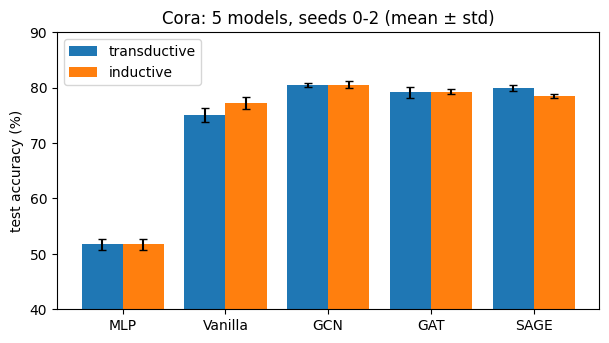

In [32]:
names = list(ind)                                      # MLP, Vanilla, GCN, GAT, SAGE
pos = torch.arange(len(names)).float()                 # 막대 위치 0 ~ 4
plt.figure(figsize=(7, 3.6))                           # 그림 크기
for k, (res, label) in enumerate([(results, "transductive"), (ind, "inductive")]):  # 두 설정
    m = [res[n].mean().item() for n in names]          # 평균
    s = [res[n].std().item() for n in names]           # 표준편차 (오차 막대)
    plt.bar(pos + (k - 0.5) * 0.4, m, width=0.4, yerr=s, capsize=3, label=label)  # 막대
plt.xticks(pos, names); plt.ylim(40, 90)               # x 축 이름 · y 범위
plt.ylabel("test accuracy (%)"); plt.title("Cora: 5 models, seeds 0-2 (mean ± std)")  # 영문
plt.legend(); plt.show()                               # 범례 · 그리기

🔍 **결과 읽는 법 — 확인한 것 / 아직 주장하지 않는 것**
- **확인한 것**: 그래프를 쓰는 네 모델은 두 설정 모두 MLP 보다 크게 높습니다. 시험 노드를 학습 그래프에서 지운 귀납 설정에서도, 학습한 가중치로 처음 보는 노드를 분류합니다.
- **아직 주장하지 않는 것**: GCN · GAT · GraphSAGE 의 순위. 차이가 표준편차와 비슷한 크기라 seed 3개로는 가릴 수 없습니다. GraphSAGE 의 장점(자기 항을 따로 두기, 이웃 샘플링으로 큰 그래프 학습)은 다음 실습의 골조 문제와 🏆 도전 과제에서 봅니다.

---
## 10. 핵심 요약

### 이론 ↔ 코드 대응표
| 이론 (강의노트) | PyG · PyTorch 코드 |
|---|---|
| 그래프 · 인용 엣지 | `data.edge_index` 📐 `[2, 엣지 수]` (윗줄 보내는 노드 → 아랫줄 받는 노드) · `to_undirected` |
| 준지도 노드 분류 | 학습 노드 140개만 채점 `out[train_mask]` · 시험은 `test_mask` |
| VanillaGNN $\tilde A X W^\top$ | `adj @ self.linear(x)` · $\tilde A$ = `to_dense_adj(edge_index)[0] + torch.eye(N)` |
| GCN $\hat A = \tilde D^{-1/2}\tilde A\tilde D^{-1/2}$ | `GCNConv` (자기 루프 · 정규화를 안에서) |
| GAT $\alpha_{ij}$ = softmax(LeakyReLU(…)) | `GATConv(heads=8)` · `att_dst` · `att_src` · `return_attention_weights=True` |
| GraphSAGE 자기 항 + 이웃 평균 | `SAGEConv` · `lin_r` ($W_{\text{self}}$) · `lin_l` ($W_{\text{nbr}}$) |
| 전이 vs 귀납 | 라벨만 가림 vs `subgraph` 로 시험 노드를 지운 그래프로 학습 |
| 공정한 비교 | 같은 뼈대 · 같은 학습 함수 · `seed_everything(0, 1, 2)` · 평균 ± 표준편차 · 기준점 MLP |

### 학습 루프 4단계 (지난 실습과 같은 뼈대!)
```python
out = model(*inputs)                              # 1️⃣ 순전파 (모든 노드)
loss = F.cross_entropy(out[mask], data.y[mask])   # 2️⃣ 학습 노드만 채점
opt.zero_grad(); loss.backward()                  # 3️⃣ 역전파
opt.step()                                        # 4️⃣ 가중치 업데이트
```

### ⚠️ 자주 하는 실수 5가지
1. 손실을 **모든 노드**로 계산 → 시험 노드의 정답을 본 셈입니다. `out[train_mask]` 로 학습 노드만!
2. `edge_index` 를 `[엣지 수, 2]` 로 만듦 → PyG 는 `[2, 엣지 수]` 입니다 (`.t()` 로 전치).
3. 한 방향 엣지만 넣음 → 메시지가 한쪽으로만 흐릅니다. 무방향 그래프는 `to_undirected` 로 양방향.
4. VanillaGNN 에 $A$ 를 그대로 넣음 → 내 피처가 다음 층으로 가지 않습니다. $\tilde A = A + I$ !
5. seed 하나로 순위를 정함 → 차이가 작으면 seed 를 바꿀 때 순위가 바뀝니다. **seed 여러 개의 평균 ± 표준편차**로 말하기.

### 🏆 도전 과제
1. `GATConv` → `GATv2Conv` 로 한 줄 바꾸기 (교재 7장 코드). 정확도와 seed 흔들림을 비교해 보세요.
2. 미니배치 이웃 샘플링 `NeighborLoader` (교재 8장): Colab 에서 `pyg_lib` 를 설치한 뒤 GraphSAGE 를 배치로 학습해 보세요. (이 노트북을 만든 PC 에는 `pyg_lib` 가 없어 이 부분은 실행하지 않았습니다.)
3. `GCNConv(..., bias=False)` 로 바꿔 VanillaGNN 과 **정규화만** 다르게 만든 뒤 비교해 보세요 — 한 번에 하나만 바꾸기.

### 교재 · 강의노트와 다른 점
- 공정한 비교를 위해 모든 모델이 같은 설정(은닉 16 · 200 에포크 · Adam 0.01 · 가중치 감쇠 5e-4 · 드롭아웃 0.5, GAT 만 논문대로 8헤드 × 8 · 0.6)을 씁니다. 교재는 장마다 설정이 달라(예: 7장 GAT 은닉 32 × 8헤드) 숫자가 조금 다릅니다.
- 교재 7장은 `GATv2Conv` 를 씁니다. 여기서는 강의노트 손계산과 맞추려고 `GATConv` 를 씁니다.
- VanillaGNN 층은 교재의 `torch.sparse.mm(adjacency, x)` 자리에 행렬 곱 `adj @ x` 를 씁니다 (밀집 행렬이라 결과는 같습니다).
- 정확도는 200 에포크가 끝난 모델로 잽니다 (검증 정확도로 시점을 고르지 않음).

### 다음 실습 예고
오늘은 논문 인용 그래프에서 **분류**를 했습니다. 다음 실습에서는 손으로 계산할 수 있는 **골조**를 그래프로 만들어, 같은 네 모델로 절점의 **변위**를 맞히고 층간변위를 검토합니다 — GraphSAGE 의 전이와 귀납이 골조에서 어떻게 달라지는지도 봅니다.